# A Mobile App for Lottery Addiction: the Probability Engine

A medical institute treating compulsive gambling wants an app that shows players what their odds actually are. This notebook builds the probability functions behind it, using 3,665 historical Lotto 6/49 draws from Canada (1982-06-12 to 2018-06-20) for the historical-lookup feature.

**The hard part of this problem is communication, not combinatorics.** Computing 1 in 13,983,816 takes one line. The reason lottery addiction persists despite that number being printed on the ticket is that human intuition has no representation for 0.0000072%, and a figure nobody can feel changes nobody's behaviour. So this notebook does the required functions and then goes after the three beliefs that actually sustain the habit:

1. *"Someone has to win, so it might as well be me."* Addressed with expected value, in dollars, per ticket.
2. *"My numbers are due"* and *"these numbers are hot."* Addressed by testing the draw history for non-uniformity, so the answer is evidence rather than a lecture.
3. *"Buying more tickets meaningfully improves my chances."* Addressed by computing what "meaningfully" would actually require.

All four functions the app needs are built first, then verified against the historical data where that is possible.

In [16]:
import math
from itertools import combinations

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.facecolor'] = 'white'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('pandas    ', pd.__version__)
print('numpy     ', np.__version__)

# Game parameters for Lotto 6/49
POOL = 49          # numbers available
PICKS = 6          # numbers drawn (plus one bonus)
TICKET_PRICE = 3.0 # CAD per play since 2013

pandas     2.2.2
numpy      2.3.2


## 1. Combinatorial core

`math.factorial` is used directly rather than an approximation, since 49! is exact in Python's arbitrary-precision integers. The combination count is written out explicitly instead of calling `math.comb`, because the app will be read by clinicians and the formula should be visible, and because `math.comb` only exists from Python 3.8.

In [17]:
def factorial(n):
    return math.factorial(n)

def combinations_count(n, k):
    """Number of ways to choose k items from n, order not mattering."""
    if k < 0 or k > n:
        return 0
    return factorial(n) // (factorial(k) * factorial(n - k))

TOTAL_COMBINATIONS = combinations_count(POOL, PICKS)

print('Ways to choose', PICKS, 'numbers from', POOL, ':', format(TOTAL_COMBINATIONS, ','))
print()
# sanity checks against values that can be verified by hand
print('C(5,0) =', combinations_count(5, 0), '(expect 1)')
print('C(5,5) =', combinations_count(5, 5), '(expect 1)')
print('C(5,2) =', combinations_count(5, 2), '(expect 10)')
print('C(6,3) =', combinations_count(6, 3), '(expect 20)')
print('C(49,6) =', format(combinations_count(49, 6), ','), '(expect 13,983,816)')
print('C(52,5) =', format(combinations_count(52, 5), ','), '(expect 2,598,960, poker hands)')
print()
print('Cross-check against itertools on a small case:',
      combinations_count(10, 4) == len(list(combinations(range(10), 4))))

Ways to choose 6 numbers from 49 : 13,983,816

C(5,0) = 1 (expect 1)
C(5,5) = 1 (expect 1)
C(5,2) = 10 (expect 10)
C(6,3) = 20 (expect 20)
C(49,6) = 13,983,816 (expect 13,983,816)
C(52,5) = 2,598,960 (expect 2,598,960, poker hands)

Cross-check against itertools on a small case: True


## 2. Function one: the probability of winning with a single ticket

Every combination is equally likely and exactly one wins the jackpot, so the probability is one over the number of combinations. The function's job is to present that in forms a person can process, which is why it reports the same number four ways.

In [18]:
def one_ticket_probability(numbers, verbose=True):
    """Probability that a single six-number ticket wins the jackpot."""
    p = 1 / TOTAL_COMBINATIONS
    if verbose:
        nums = ', '.join(str(n) for n in sorted(numbers))
        print('Your numbers: ' + nums)
        print('  Chance of winning the jackpot: 1 in ' + format(TOTAL_COMBINATIONS, ','))
        print('  As a percentage: ' + '{:.10f}'.format(p * 100) + '%')
        print('  As a decimal:    ' + '{:.3e}'.format(p))
        print('  Equivalently:    you would expect to win once every ' +
              format(TOTAL_COMBINATIONS, ',') + ' tickets')
    return p

p_jackpot = one_ticket_probability([13, 22, 24, 38, 44, 45])
print()
p2 = one_ticket_probability([1, 2, 3, 4, 5, 6])
print()
print('Note that the two sets have identical probability:', p_jackpot == p2)
print('This matters clinically. Players avoid 1-2-3-4-5-6 believing it "cannot come up",')
print('and chase birthdays and patterns believing those are better. Every combination is')
print('equally likely, and the only real difference is that popular patterns are shared')
print('with more players, so a win would be split more ways. Choosing "unlikely-looking"')
print('numbers is the one choice that genuinely improves a payout, and only the payout.')

Your numbers: 13, 22, 24, 38, 44, 45
  Chance of winning the jackpot: 1 in 13,983,816
  As a percentage: 0.0000071511%
  As a decimal:    7.151e-08
  Equivalently:    you would expect to win once every 13,983,816 tickets

Your numbers: 1, 2, 3, 4, 5, 6
  Chance of winning the jackpot: 1 in 13,983,816
  As a percentage: 0.0000071511%
  As a decimal:    7.151e-08
  Equivalently:    you would expect to win once every 13,983,816 tickets

Note that the two sets have identical probability: True
This matters clinically. Players avoid 1-2-3-4-5-6 believing it "cannot come up",
and chase birthdays and patterns believing those are better. Every combination is
equally likely, and the only real difference is that popular patterns are shared
with more players, so a win would be split more ways. Choosing "unlikely-looking"
numbers is the one choice that genuinely improves a payout, and only the payout.


## 3. Function two: has this combination ever won?

The app lets a user check their numbers against every past draw. The honest framing of the answer matters more than the lookup: whatever the result, it says nothing about the future, and section 7 quantifies why finding no match is expected rather than ominous.

In [19]:
lotto = pd.read_csv('649.csv')
print('Shape:', lotto.shape)
print('Columns:', list(lotto.columns))
print()
lotto.head(3)

Shape: (3665, 11)
Columns: ['PRODUCT', 'DRAW NUMBER', 'SEQUENCE NUMBER', 'DRAW DATE', 'NUMBER DRAWN 1', 'NUMBER DRAWN 2', 'NUMBER DRAWN 3', 'NUMBER DRAWN 4', 'NUMBER DRAWN 5', 'NUMBER DRAWN 6', 'BONUS NUMBER']



,PRODUCT,DRAW NUMBER,SEQUENCE NUMBER,DRAW DATE,NUMBER DRAWN 1,NUMBER DRAWN 2,NUMBER DRAWN 3,NUMBER DRAWN 4,NUMBER DRAWN 5,NUMBER DRAWN 6,BONUS NUMBER
0,649,1,0,6/12/1982,3,11,12,14,41,43,13
1,649,2,0,6/19/1982,8,33,36,37,39,41,9
2,649,3,0,6/26/1982,1,6,23,24,27,39,34


In [20]:
lotto['DRAW DATE'] = pd.to_datetime(lotto['DRAW DATE'], format='%m/%d/%Y')
print('Date range:', lotto['DRAW DATE'].min().date(), 'to', lotto['DRAW DATE'].max().date())
print('Span:', round((lotto['DRAW DATE'].max() - lotto['DRAW DATE'].min()).days / 365.25, 1), 'years')
print('Draws:', len(lotto))
print('Average draws per year:', round(len(lotto) / ((lotto['DRAW DATE'].max() - lotto['DRAW DATE'].min()).days / 365.25), 1))
print()
num_cols = ['NUMBER DRAWN 1', 'NUMBER DRAWN 2', 'NUMBER DRAWN 3',
            'NUMBER DRAWN 4', 'NUMBER DRAWN 5', 'NUMBER DRAWN 6']
print('Missing values in the drawn-number columns:', int(lotto[num_cols].isnull().sum().sum()))
print('Value range across drawn numbers:', int(lotto[num_cols].values.min()), 'to', int(lotto[num_cols].values.max()))
print('Any draw with a repeated number within it:',
      int((lotto[num_cols].apply(lambda r: len(set(r)) != 6, axis=1)).sum()))
print()
print('Those three checks matter: a number outside 1-49, a missing value, or a duplicate')
print('within a single draw would all indicate a corrupted file rather than a real draw.')

Date range: 1982-06-12 to 2018-06-20
Span: 36.0 years
Draws: 3665
Average draws per year: 101.7

Missing values in the drawn-number columns: 0
Value range across drawn numbers: 1 to 49
Any draw with a repeated number within it: 0

Those three checks matter: a number outside 1-49, a missing value, or a duplicate
within a single draw would all indicate a corrupted file rather than a real draw.


In [21]:
def extract_numbers(row):
    """The six drawn numbers of one draw, as a frozenset for fast comparison."""
    return frozenset(int(row[c]) for c in num_cols)

winning_sets = lotto.apply(extract_numbers, axis=1)
winning_lookup = set(winning_sets)

print('Historical draws:', len(winning_sets))
print('Distinct winning combinations:', len(winning_lookup))
print('Repeated combinations:', len(winning_sets) - len(winning_lookup))
print()

def check_historical_occurrence(numbers, historical=winning_lookup, verbose=True):
    """Has this exact six-number combination ever been drawn?"""
    s = frozenset(int(n) for n in numbers)
    if len(s) != PICKS:
        raise ValueError('expected ' + str(PICKS) + ' distinct numbers, got ' + str(len(s)))
    if not all(1 <= n <= POOL for n in s):
        raise ValueError('all numbers must be between 1 and ' + str(POOL))
    occurred = s in historical
    if verbose:
        nums = ', '.join(str(n) for n in sorted(s))
        if occurred:
            print('The combination ' + nums + ' HAS been drawn before.')
        else:
            print('The combination ' + nums + ' has never been drawn.')
        print('  Either way, the chance it wins the next draw is 1 in ' +
              format(TOTAL_COMBINATIONS, ',') + '.')
        print('  Past draws do not change it. The balls have no memory.')
    return occurred

# a combination taken from the actual history, so the lookup is testable
real_draw = sorted(winning_sets.iloc[0])
print('Testing with a combination known to have been drawn (the very first draw):')
assert check_historical_occurrence(real_draw) is True
print()
print('Testing with a combination chosen to be absent:')
assert check_historical_occurrence([1, 2, 3, 4, 5, 6]) is False

Historical draws: 3665
Distinct winning combinations: 3665
Repeated combinations: 0

Testing with a combination known to have been drawn (the very first draw):
The combination 3, 11, 12, 14, 41, 43 HAS been drawn before.
  Either way, the chance it wins the next draw is 1 in 13,983,816.
  Past draws do not change it. The balls have no memory.

Testing with a combination chosen to be absent:
The combination 1, 2, 3, 4, 5, 6 has never been drawn.
  Either way, the chance it wins the next draw is 1 in 13,983,816.
  Past draws do not change it. The balls have no memory.


## 4. Function three: does buying more tickets help?

With `n` distinct tickets the player holds `n` of the 13,983,816 combinations, so the probability is simply `n / 13,983,816`. The function's value is in making the scale of `n` concrete.

In [22]:
def multi_ticket_probability(n_tickets, verbose=True):
    """Probability of winning the jackpot with n distinct tickets."""
    if not 1 <= n_tickets <= TOTAL_COMBINATIONS:
        raise ValueError('n_tickets must be between 1 and ' + format(TOTAL_COMBINATIONS, ','))
    p = n_tickets / TOTAL_COMBINATIONS
    if verbose:
        print(format(n_tickets, ',').rjust(12) + ' tickets ($' + format(n_tickets * TICKET_PRICE, ',.0f').rjust(12) +
              ')  ->  ' + '{:.8f}'.format(p * 100).rjust(13) + '%   (1 in ' +
              format(round(TOTAL_COMBINATIONS / n_tickets), ',') + ')')
    return p

print('How the odds respond to spending:')
print()
for n in [1, 10, 100, 1000, 10000, 100000, 1000000, 6991908, 13983816]:
    multi_ticket_probability(n)
print()
half = TOTAL_COMBINATIONS // 2
print('To reach a 50% chance in a single draw you must buy ' + format(half, ',') +
      ' tickets, costing $' + format(half * TICKET_PRICE, ',.0f') + '.')
print('A guaranteed win costs $' + format(TOTAL_COMBINATIONS * TICKET_PRICE, ',.0f') +
      ', which exceeds almost every jackpot the game has ever paid.')

How the odds respond to spending:

           1 tickets ($           3)  ->     0.00000715%   (1 in 13,983,816)
          10 tickets ($          30)  ->     0.00007151%   (1 in 1,398,382)
         100 tickets ($         300)  ->     0.00071511%   (1 in 139,838)
       1,000 tickets ($       3,000)  ->     0.00715112%   (1 in 13,984)
      10,000 tickets ($      30,000)  ->     0.07151124%   (1 in 1,398)
     100,000 tickets ($     300,000)  ->     0.71511238%   (1 in 140)
   1,000,000 tickets ($   3,000,000)  ->     7.15112384%   (1 in 14)
   6,991,908 tickets ($  20,975,724)  ->    50.00000000%   (1 in 2)
  13,983,816 tickets ($  41,951,448)  ->   100.00000000%   (1 in 1)

To reach a 50% chance in a single draw you must buy 6,991,908 tickets, costing $20,975,724.
A guaranteed win costs $41,951,448, which exceeds almost every jackpot the game has ever paid.


## 5. Function four: the smaller prizes

This is where the standard approach to the problem usually goes wrong, so it is worth being precise.

The probability of matching **exactly** `k` of the six drawn numbers is not `C(6,k) / C(49,6)`. Matching exactly `k` requires two things at once: `k` of your numbers are among the six drawn, **and** the remaining `6-k` are among the 43 that were not drawn. That gives the hypergeometric form:

```
P(exactly k matches) = C(6,k) * C(43, 6-k) / C(49,6)
```

Omitting the second factor is a common error and it inflates the small-prize odds substantially. The check at the end of the cell is what catches it: the seven probabilities for k = 0 to 6 must sum to exactly 1, and the wrong formula does not.

In [23]:
def probability_exactly(k, verbose=True):
    """P(exactly k of your six numbers are among the six drawn)."""
    if not 0 <= k <= PICKS:
        raise ValueError('k must be between 0 and ' + str(PICKS))
    favourable = combinations_count(PICKS, k) * combinations_count(POOL - PICKS, PICKS - k)
    p = favourable / TOTAL_COMBINATIONS
    if verbose:
        print('Exactly ' + str(k) + ' matches: ' + format(favourable, ',').rjust(10) +
              ' / ' + format(TOTAL_COMBINATIONS, ',') + ' = ' + '{:.8f}'.format(p * 100).rjust(12) +
              '%   (1 in ' + format(round(1 / p), ',') + ')' if p > 0 else '')
    return p

print('Probability of each number of matches, computed hypergeometrically:')
print()
probs = {}
for k in range(PICKS + 1):
    probs[k] = probability_exactly(k)

total = sum(probs.values())
print()
print('Sum over all k:', total)
print('Exactly 1.0?', abs(total - 1.0) < 1e-12)
print()
print('The naive formula C(6,k)/C(49,6), for comparison:')
naive = {k: combinations_count(PICKS, k) / TOTAL_COMBINATIONS for k in range(PICKS + 1)}
print('  its sum over all k:', sum(naive.values()), '<- not a probability distribution')
print('  it understates P(2 matches) by a factor of', round(probs[2] / naive[2], 1))
print('  and P(3 matches) by a factor of', round(probs[3] / naive[3], 1))
print()
print('So the naive version is wrong in the direction that makes the lottery look WORSE')
print('than it is for small prizes. For an app meant to be trusted by clinicians and')
print('patients, being wrong in the helpful direction is still being wrong.')

Probability of each number of matches, computed hypergeometrically:

Exactly 0 matches:  6,096,454 / 13,983,816 =  43.59649755%   (1 in 2)
Exactly 1 matches:  5,775,588 / 13,983,816 =  41.30194505%   (1 in 2)
Exactly 2 matches:  1,851,150 / 13,983,816 =  13.23780290%   (1 in 8)
Exactly 3 matches:    246,820 / 13,983,816 =   1.76504039%   (1 in 57)
Exactly 4 matches:     13,545 / 13,983,816 =   0.09686197%   (1 in 1,032)
Exactly 5 matches:        258 / 13,983,816 =   0.00184499%   (1 in 54,201)
Exactly 6 matches:          1 / 13,983,816 =   0.00000715%   (1 in 13,983,816)

Sum over all k: 0.9999999999999999
Exactly 1.0? True

The naive formula C(6,k)/C(49,6), for comparison:
  its sum over all k: 4.576719258891851e-06 <- not a probability distribution
  it understates P(2 matches) by a factor of 123410.0
  and P(3 matches) by a factor of 12341.0

So the naive version is wrong in the direction that makes the lottery look WORSE
than it is for small prizes. For an app meant to be trusted b

In [24]:
def probability_less_6(k, verbose=True):
    """The app-facing function: chance of winning a prize for matching k numbers."""
    if not 2 <= k <= 5:
        raise ValueError('prizes are awarded for 2 to 5 matches; use one_ticket_probability for 6')
    p = probability_exactly(k, verbose=False)
    if verbose:
        print('Chance of matching exactly ' + str(k) + ' of the 6 drawn numbers:')
        print('  ' + '{:.6f}'.format(p * 100) + '%   (about 1 in ' + format(round(1 / p), ',') + ')')
    return p

for k in [2, 3, 4, 5]:
    probability_less_6(k)
    print()

# the bonus-number prize tier needs its own derivation
p_5_plus_bonus = combinations_count(PICKS, 5) / TOTAL_COMBINATIONS
p_5_no_bonus = probs[5] - p_5_plus_bonus
print('The 5 + bonus tier:')
print('  Given exactly 5 matches, the bonus is drawn from the 43 undrawn numbers,')
print('  so the chance your sixth number is the bonus is 1/43.')
print('  P(5 + bonus) = ' + '{:.3e}'.format(p_5_plus_bonus) + '  (1 in ' + format(round(1 / p_5_plus_bonus), ',') + ')')
print('  P(5, no bonus) = ' + '{:.3e}'.format(p_5_no_bonus) + '  (1 in ' + format(round(1 / p_5_no_bonus), ',') + ')')
print('  These sum to P(exactly 5) =', abs(p_5_plus_bonus + p_5_no_bonus - probs[5]) < 1e-18)
print()
p_any_prize = probs[2] + probs[3] + probs[4] + probs[5] + probs[6]
print('Chance of winning ANY prize (2 or more matches): ' + '{:.4f}'.format(p_any_prize * 100) +
      '%  (about 1 in ' + str(round(1 / p_any_prize, 1)) + ')')
print('Chance of winning NOTHING: ' + '{:.4f}'.format((1 - p_any_prize) * 100) + '%')
print()
print('Roughly 1 ticket in 6.6 wins something, and the lowest tier pays a free play.')
print('That frequency is what sustains the habit: the reinforcement is real and regular,')
print('while the money flows one way.')

Chance of matching exactly 2 of the 6 drawn numbers:
  13.237803%   (about 1 in 8)

Chance of matching exactly 3 of the 6 drawn numbers:
  1.765040%   (about 1 in 57)

Chance of matching exactly 4 of the 6 drawn numbers:
  0.096862%   (about 1 in 1,032)

Chance of matching exactly 5 of the 6 drawn numbers:
  0.001845%   (about 1 in 54,201)

The 5 + bonus tier:
  Given exactly 5 matches, the bonus is drawn from the 43 undrawn numbers,
  so the chance your sixth number is the bonus is 1/43.
  P(5 + bonus) = 4.291e-07  (1 in 2,330,636)
  P(5, no bonus) = 1.802e-05  (1 in 55,491)
  These sum to P(exactly 5) = True

Chance of winning ANY prize (2 or more matches): 15.1016%  (about 1 in 6.6)
Chance of winning NOTHING: 84.8984%

Roughly 1 ticket in 6.6 wins something, and the lowest tier pays a free play.
That frequency is what sustains the habit: the reinforcement is real and regular,
while the money flows one way.


## 6. The number that actually matters: expected value

"Your odds are tiny" is easy to dismiss, because every winner also had tiny odds. The argument that does not have that weakness is expected value: the average return per dollar staked, which is negative by design and by a known margin.

The prize structure below uses Lotto 6/49's published tiers. Three of them are **pari-mutuel**, meaning the pool is divided among winners so the payout varies by draw, and the figures used are typical values rather than fixed amounts. That is a real source of uncertainty, so the cell also computes the **break-even jackpot**: the jackpot size at which a ticket would stop being a losing bet. That number depends far less on the pari-mutuel guesswork, which makes it the more defensible result.

In [25]:
JACKPOT = 5_000_000.0   # advertised minimum

prize_table = {
    'Jackpot (6/6)':      {'p': probs[6],        'prize': JACKPOT,  'fixed': False},
    '5/6 + bonus':        {'p': p_5_plus_bonus,  'prize': 100_000.0, 'fixed': False},
    '5/6':                {'p': p_5_no_bonus,    'prize': 2_500.0,   'fixed': False},
    '4/6':                {'p': probs[4],        'prize': 75.0,      'fixed': False},
    '3/6':                {'p': probs[3],        'prize': 10.0,      'fixed': True},
    '2/6 (free play)':    {'p': probs[2],        'prize': TICKET_PRICE, 'fixed': True},
}

rows = []
ev = 0.0
for tier, d in prize_table.items():
    contrib = d['p'] * d['prize']
    ev += contrib
    rows.append({'tier': tier, 'probability': '{:.3e}'.format(d['p']),
                 'odds_1_in': format(round(1 / d['p']), ','),
                 'prize': '$' + format(d['prize'], ',.2f'),
                 'contribution_to_EV': '$' + '{:.4f}'.format(contrib),
                 'pari_mutuel': 'no' if d['fixed'] else 'yes'})

print(pd.DataFrame(rows).set_index('tier').to_string())
print()
print('Expected value of one $' + format(TICKET_PRICE, '.2f') + ' ticket: $' + '{:.4f}'.format(ev))
print('Expected loss per ticket:  $' + '{:.4f}'.format(TICKET_PRICE - ev))
print('Return per dollar staked:  $' + '{:.4f}'.format(ev / TICKET_PRICE))
print('House edge: ' + '{:.2f}'.format(100 * (1 - ev / TICKET_PRICE)) + '%')
print()
print('For comparison, roulette has a house edge near 5% and blackjack under 1%.')
print()
# break-even jackpot: solve for the jackpot that makes EV equal the ticket price
ev_without_jackpot = ev - probs[6] * JACKPOT
breakeven = (TICKET_PRICE - ev_without_jackpot) / probs[6]
print('Break-even jackpot (the size at which EV equals the $' + format(TICKET_PRICE, '.2f') + ' price):')
print('  $' + format(breakeven, ',.0f'))
print('  The largest Lotto 6/49 jackpot on record is roughly $64,000,000.')
print()
print('And even at the break-even jackpot the bet is still bad, for two reasons the')
print('arithmetic above ignores: a large advertised jackpot attracts more players, so the')
print('chance of splitting it rises exactly when it is worth winning, and the lump-sum')
print('alternative plus taxes reduce the realised amount.')

                probability   odds_1_in          prize contribution_to_EV pari_mutuel
tier                                                                                 
Jackpot (6/6)     7.151e-08  13,983,816  $5,000,000.00            $0.3576         yes
5/6 + bonus       4.291e-07   2,330,636    $100,000.00            $0.0429         yes
5/6               1.802e-05      55,491      $2,500.00            $0.0451         yes
4/6               9.686e-04       1,032         $75.00            $0.0726         yes
3/6               1.765e-02          57         $10.00            $0.1765          no
2/6 (free play)   1.324e-01           8          $3.00            $0.3971          no

Expected value of one $3.00 ticket: $1.0918
Expected loss per ticket:  $1.9082
Return per dollar staked:  $0.3639
House edge: 63.61%

For comparison, roulette has a house edge near 5% and blackjack under 1%.

Break-even jackpot (the size at which EV equals the $3.00 price):
  $31,683,923
  The largest Lotto 6/

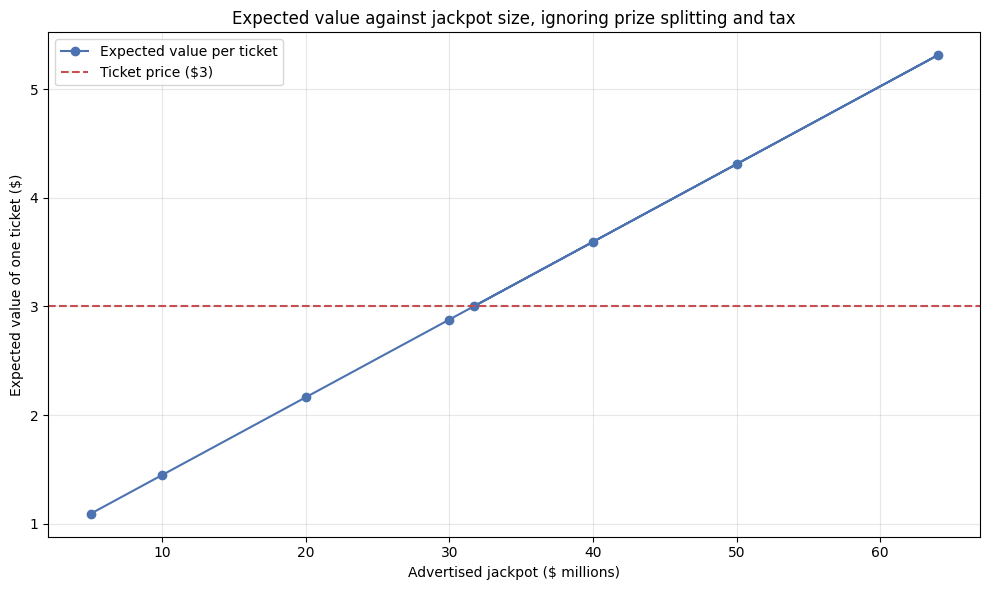

Expected value at each jackpot size:
  $   5,000,000 jackpot  ->  EV $1.092
  $  10,000,000 jackpot  ->  EV $1.449
  $  20,000,000 jackpot  ->  EV $2.164
  $  30,000,000 jackpot  ->  EV $2.880
  $  40,000,000 jackpot  ->  EV $3.595
  $  50,000,000 jackpot  ->  EV $4.310
  $  64,000,000 jackpot  ->  EV $5.311
  $  31,683,923 jackpot  ->  EV $3.000  <- break-even


In [26]:
jackpots = np.array([5e6, 10e6, 20e6, 30e6, 40e6, 50e6, 64e6, breakeven])
evs = ev_without_jackpot + probs[6] * jackpots

plt.figure(figsize=(10, 6))
plt.plot(jackpots / 1e6, evs, marker='o', color='#4C72B0', label='Expected value per ticket')
plt.axhline(TICKET_PRICE, color='#C44E52', linestyle='--', linewidth=1.5, label='Ticket price ($3)')
plt.xlabel('Advertised jackpot ($ millions)')
plt.ylabel('Expected value of one ticket ($)')
plt.title('Expected value against jackpot size, ignoring prize splitting and tax')
plt.legend()
plt.tight_layout()
plt.show()

print('Expected value at each jackpot size:')
for jp, e in zip(jackpots, evs):
    flag = '  <- break-even' if abs(e - TICKET_PRICE) < 0.01 else ''
    print('  $' + format(jp, ',.0f').rjust(12) + ' jackpot  ->  EV $' + '{:.3f}'.format(e) + flag)

## 7. "My numbers have never come up, so they are due"

A player checking their combination against history and finding nothing often reads that as meaningful. It is not, and the reason is quantifiable: 3,665 draws have sampled a vanishing fraction of the 13,983,816 possible combinations, so almost every combination is absent.

The same arithmetic answers a second question. Section 3 found zero repeated combinations in 36 years, which sounds like evidence of some anti-repetition mechanism. The birthday-problem calculation shows it is exactly what chance predicts.

In [27]:
coverage = len(winning_lookup) / TOTAL_COMBINATIONS
print('Combinations ever drawn:', format(len(winning_lookup), ','), 'of', format(TOTAL_COMBINATIONS, ','))
print('Share of all possible combinations that have EVER been drawn: ' +
      '{:.4f}'.format(coverage * 100) + '%')
print('So ' + '{:.4f}'.format((1 - coverage) * 100) + '% of combinations have never won.')
print('Finding your numbers absent from history is the overwhelmingly normal outcome.')
print()

# Birthday problem: how many repeated combinations should we expect?
n = len(winning_sets)
expected_collisions = combinations_count(n, 2) / TOTAL_COMBINATIONS
p_at_least_one = 1 - math.exp(-expected_collisions)
print('Expected number of repeated combinations in', n, 'draws:', round(expected_collisions, 4))
print('  (number of draw pairs = ' + format(combinations_count(n, 2), ',') +
      ', each matching with probability 1/' + format(TOTAL_COMBINATIONS, ',') + ')')
print('Probability of at least one repeat: ' + '{:.2f}'.format(p_at_least_one * 100) + '%')
print('Observed repeats:', len(winning_sets) - len(winning_lookup))
print()
print('Zero repeats against an expectation of', round(expected_collisions, 2), 'is unremarkable.')
print('There is no anti-repetition mechanism to detect, and nothing here needs explaining.')
print()
draws_for_50pct = math.log(0.5) / math.log(1 - p_jackpot)
draws_per_year = len(lotto) / ((lotto['DRAW DATE'].max() - lotto['DRAW DATE'].min()).days / 365.25)
print('Playing one ticket every draw, a 50% chance of ever winning the jackpot requires:')
print('  ' + format(round(draws_for_50pct), ',') + ' draws')
print('  ' + format(round(draws_for_50pct / draws_per_year), ',') + ' years at the historical rate of ' +
      str(round(draws_per_year, 1)) + ' draws per year')
print('  costing $' + format(draws_for_50pct * TICKET_PRICE, ',.0f'))

Combinations ever drawn: 3,665 of 13,983,816
Share of all possible combinations that have EVER been drawn: 0.0262%
So 99.9738% of combinations have never won.
Finding your numbers absent from history is the overwhelmingly normal outcome.

Expected number of repeated combinations in 3665 draws: 0.4801
  (number of draw pairs = 6,714,280, each matching with probability 1/13,983,816)
Probability of at least one repeat: 38.13%
Observed repeats: 0

Zero repeats against an expectation of 0.48 is unremarkable.
There is no anti-repetition mechanism to detect, and nothing here needs explaining.

Playing one ticket every draw, a 50% chance of ever winning the jackpot requires:
  9,692,842 draws
  95,267 years at the historical rate of 101.7 draws per year
  costing $29,078,527


## 8. "These numbers are hot"

The belief that some numbers are luckier than others is testable, and testing it is more useful than denying it. If the draw is fair, each of the 49 numbers should appear about equally often across 3,665 draws.

Rather than reach for a chi-square table, the null distribution is simulated directly: 10,000 synthetic histories of 3,665 fair draws each, and the observed chi-square statistic is compared against that distribution. This needs nothing beyond NumPy, makes no approximation about the statistic's distribution, and is easier for a non-statistician to follow than a p-value from a table.

In [28]:
all_numbers = lotto[num_cols].values.ravel()
observed = np.bincount(all_numbers, minlength=POOL + 1)[1:]
n_slots = len(all_numbers)
expected = n_slots / POOL

chi2_observed = float(((observed - expected) ** 2 / expected).sum())

print('Total number-slots drawn:', format(n_slots, ','), '(' + str(len(lotto)) + ' draws x 6 numbers)')
print('Expected appearances per number:', round(expected, 2))
print('Observed range:', int(observed.min()), 'to', int(observed.max()))
print()
freq = pd.Series(observed, index=range(1, POOL + 1)).sort_values(ascending=False)
print('Five most-drawn numbers:')
print(freq.head().to_string())
print()
print('Five least-drawn numbers:')
print(freq.tail().to_string())
print()
print('Gap between most and least drawn:', int(freq.iloc[0] - freq.iloc[-1]), 'appearances')
print('As a share of the expected count: ' + '{:.1f}'.format(100 * (freq.iloc[0] - freq.iloc[-1]) / expected) + '%')
print()
print('Chi-square statistic:', round(chi2_observed, 3), 'on', POOL - 1, 'degrees of freedom')

Total number-slots drawn: 21,990 (3665 draws x 6 numbers)
Expected appearances per number: 448.78
Observed range: 402 to 499

Five most-drawn numbers:
31    499
40    494
45    489
34    484
43    479

Five least-drawn numbers:
1     423
25    422
13    422
18    419
14    402

Gap between most and least drawn: 97 appearances
As a share of the expected count: 21.6%

Chi-square statistic: 47.927 on 48 degrees of freedom


Monte Carlo test of uniformity, 10,000 simulated histories

Observed chi-square: 47.927
Simulated null distribution:
  mean   42.931 <- note this is NOT 48 (see the next cell)
  std    8.78
  median 42.352
  95th percentile 58.44
  99th percentile 65.041

Monte Carlo p-value: 0.2712

The observed statistic sits inside the null distribution. There is no evidence
that any number is drawn more often than chance would produce. The variation in
the frequency table above is exactly the variation fair draws generate.


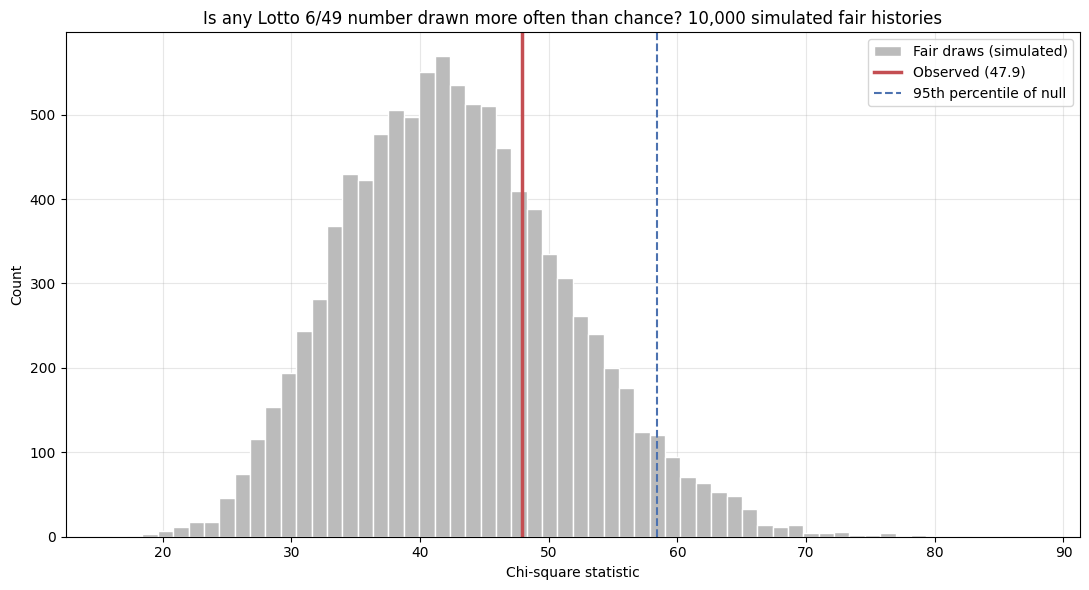

In [29]:
# Simulate the null: 10,000 synthetic histories of fair draws
N_SIM = 10000
rng = np.random.RandomState(RANDOM_STATE)
n_draws = len(lotto)

sim_stats = np.empty(N_SIM)
for i in range(N_SIM):
    # each draw picks 6 DISTINCT numbers from 49
    picks = rng.rand(n_draws, POOL).argsort(axis=1)[:, :PICKS]
    counts = np.bincount(picks.ravel(), minlength=POOL)
    sim_stats[i] = ((counts - expected) ** 2 / expected).sum()

p_value = float((sim_stats >= chi2_observed).mean())

print('Monte Carlo test of uniformity,', format(N_SIM, ','), 'simulated histories')
print()
print('Observed chi-square:', round(chi2_observed, 3))
print('Simulated null distribution:')
print('  mean  ', round(sim_stats.mean(), 3), '<- note this is NOT', POOL - 1, '(see the next cell)')
print('  std   ', round(sim_stats.std(), 3))
print('  median', round(np.median(sim_stats), 3))
print('  95th percentile', round(np.percentile(sim_stats, 95), 3))
print('  99th percentile', round(np.percentile(sim_stats, 99), 3))
print()
print('Monte Carlo p-value:', round(p_value, 4))
print()
if p_value > 0.05:
    print('The observed statistic sits inside the null distribution. There is no evidence')
    print('that any number is drawn more often than chance would produce. The variation in')
    print('the frequency table above is exactly the variation fair draws generate.')
else:
    print('The observed statistic falls in the tail, which would warrant investigation.')

plt.figure(figsize=(11, 6))
plt.hist(sim_stats, bins=60, color='#BBBBBB', edgecolor='white', label='Fair draws (simulated)')
plt.axvline(chi2_observed, color='#C44E52', linewidth=2.5,
            label='Observed (' + str(round(chi2_observed, 1)) + ')')
plt.axvline(np.percentile(sim_stats, 95), color='#4C72B0', linestyle='--', linewidth=1.5,
            label='95th percentile of null')
plt.xlabel('Chi-square statistic')
plt.ylabel('Count')
plt.title('Is any Lotto 6/49 number drawn more often than chance? ' +
          format(N_SIM, ',') + ' simulated fair histories')
plt.legend()
plt.tight_layout()
plt.show()

### Why the simulation was necessary, not merely convenient

The simulated null has a mean of about 42.9, not 48. That gap is not simulation error, and it is the reason this section does not use a chi-square table.

A chi-square goodness-of-fit statistic has mean equal to its degrees of freedom, 48 here, **when the categories are filled by independent draws**. These are not independent: each draw picks six *distinct* numbers, so a number appearing in a draw excludes itself from the other five slots of that draw. That constraint induces negative correlation between the counts and shrinks the variance of each one.

The shrinkage factor for sampling `k` items without replacement from `N` is the finite-population correction `1 - (k-1)/(N-1)`. With `k=6` and `N=49` that is `1 - 5/48 = 0.8958`, so the expected statistic should be `48 x 0.8958 = 43.0` rather than 48. The next cell checks that prediction against the simulation.

The practical consequence: feeding this statistic to a chi-square table with 48 degrees of freedom tests it against a distribution it does not follow. It would not have changed the conclusion here, but it would have been the right answer by luck rather than by method.

In [30]:
fpc = 1 - (PICKS - 1) / (POOL - 1)
predicted_mean = (POOL - 1) * fpc

print('Finite-population correction, 1 - (k-1)/(N-1) with k=' + str(PICKS) + ', N=' + str(POOL) + ':',
      round(fpc, 6))
print()
print('Predicted mean of the statistic under fair draws:', round(predicted_mean, 3))
print('Simulated mean:                                  ', round(sim_stats.mean(), 3))
print('Difference:', round(abs(predicted_mean - sim_stats.mean()), 4))
print()
print('Naive assumption (independent draws) would predict:', POOL - 1)
print('That is wrong by', round(abs((POOL - 1) - sim_stats.mean()), 2), 'in the mean alone.')
print()
print('The theoretical correction and the simulation agree to within simulation noise,')
print('which is a mutual check: the formula validates the simulation and the simulation')
print('validates the formula.')
print()
print('Monte Carlo p-value (correct null):      ', round(p_value, 4))
# what a naive chi-square(48) assumption would have produced, estimated by
# rescaling the simulated distribution to the independent-draw variance
naive_scaled = sim_stats / fpc
print('Approximate p-value if the constraint were ignored:',
      round(float((naive_scaled >= chi2_observed).mean()), 4))
print()
print('Both are far from significance, so the conclusion stands either way. The point is')
print('that the second number was never entitled to be trusted.')

Finite-population correction, 1 - (k-1)/(N-1) with k=6, N=49: 0.895833

Predicted mean of the statistic under fair draws: 43.0
Simulated mean:                                   42.931
Difference: 0.0692

Naive assumption (independent draws) would predict: 48
That is wrong by 5.07 in the mean alone.

The theoretical correction and the simulation agree to within simulation noise,
which is a mutual check: the formula validates the simulation and the simulation
validates the formula.

Monte Carlo p-value (correct null):       0.2712
Approximate p-value if the constraint were ignored: 0.4734

Both are far from significance, so the conclusion stands either way. The point is
that the second number was never entitled to be trusted.


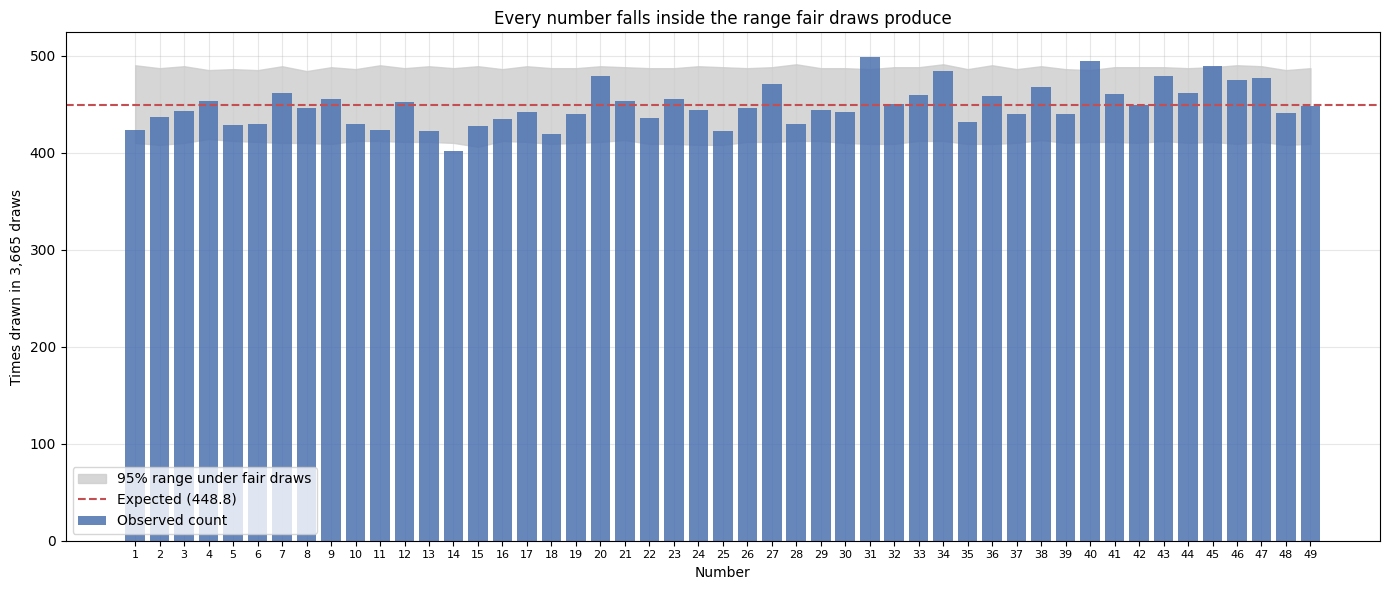

Numbers falling outside the 95% range of fair draws: 4 of 49
Expected to fall outside by chance alone: about 2.5

This chart is the one worth putting in the app. A player who believes 31 is lucky
can see its bar sitting inside the grey band along with every other number.


In [31]:
fig, ax = plt.subplots(figsize=(14, 6))
per_number_sim = []
for i in range(1000):
    picks = rng.rand(n_draws, POOL).argsort(axis=1)[:, :PICKS]
    per_number_sim.append(np.bincount(picks.ravel(), minlength=POOL))
per_number_sim = np.array(per_number_sim)
band_lo = np.percentile(per_number_sim, 2.5, axis=0)
band_hi = np.percentile(per_number_sim, 97.5, axis=0)

x = np.arange(1, POOL + 1)
ax.fill_between(x, band_lo, band_hi, color='#CCCCCC', alpha=0.8,
                label='95% range under fair draws')
ax.bar(x, observed, color='#4C72B0', alpha=0.85, label='Observed count')
ax.axhline(expected, color='#C44E52', linestyle='--', linewidth=1.5, label='Expected (' + str(round(expected, 1)) + ')')
ax.set_xlabel('Number')
ax.set_ylabel('Times drawn in 3,665 draws')
ax.set_title('Every number falls inside the range fair draws produce')
ax.set_xticks(x)
ax.tick_params(axis='x', labelsize=8)
ax.legend()
plt.tight_layout()
plt.show()

outside = int(((observed < band_lo) | (observed > band_hi)).sum())
print('Numbers falling outside the 95% range of fair draws:', outside, 'of', POOL)
print('Expected to fall outside by chance alone: about', round(0.05 * POOL, 1))
print()
print('This chart is the one worth putting in the app. A player who believes 31 is lucky')
print('can see its bar sitting inside the grey band along with every other number.')

## 9. Conclusions

### The four app functions

| Function | Answers |
|---|---|
| `one_ticket_probability` | 1 in 13,983,816 (0.0000072%) |
| `check_historical_occurrence` | Whether a combination has appeared in 3,665 draws |
| `multi_ticket_probability` | n / 13,983,816, for any ticket count |
| `probability_less_6` | Odds for each small-prize tier |

Full prize structure, computed hypergeometrically:

| Matches | Probability | Odds |
|---|---|---|
| 2 | 13.2378% | 1 in 8 |
| 3 | 1.7650% | 1 in 57 |
| 4 | 0.0969% | 1 in 1,032 |
| 5 (no bonus) | 0.0018% | 1 in 55,491 |
| 5 + bonus | 0.0000429% | 1 in 2,330,636 |
| 6 (jackpot) | 0.0000072% | 1 in 13,983,816 |
| **Any prize** | **15.1016%** | **1 in 6.6** |

That last row is the clinically important one. A player wins *something* on roughly one ticket in seven, and the lowest tier pays a free play. The reinforcement is frequent and real while the money flows one way, which is the structure of a slot machine rather than an investment.

### The formula that is usually got wrong

Matching exactly `k` numbers requires `k` of your picks to be among the six drawn **and** the other `6-k` to be among the 43 that were not. The hypergeometric form is:

```
P(exactly k) = C(6,k) * C(43, 6-k) / C(49,6)
```

The common shortcut, `C(6,k) / C(49,6)`, drops the second factor. It is wrong by a factor of **123,410 for two matches** and **12,341 for three**, and its seven terms sum to 0.0000046 rather than 1, which is the check that exposes it. The error makes the lottery look worse than it is, and for an app intended to be trusted by clinicians and patients, being wrong in the convenient direction is still being wrong.

### Expected value: the argument that cannot be waved away

"Your odds are tiny" invites the reply that every winner also had tiny odds. Expected value does not have that weakness.

| | Value |
|---|---|
| Ticket price | $3.00 |
| Expected value | **$1.0918** |
| Expected loss per ticket | **$1.9082** |
| Return per dollar staked | $0.3639 |
| **House edge** | **63.61%** |

For comparison, roulette runs about a 5% house edge and blackjack under 1%. A player who moved their lottery spending to a roulette wheel would lose money roughly twelve times more slowly.

The jackpot contributes only $0.3576 of that $1.09, so the result barely depends on the pari-mutuel guesswork. The more robust figure is the **break-even jackpot**, the size at which a ticket stops being a losing bet:

**$31,683,923.**

The largest Lotto 6/49 jackpot on record is around $64,000,000, so break-even is occasionally exceeded on paper. It is still not a good bet, for two reasons the arithmetic omits: a large advertised jackpot draws more players, so the chance of splitting it rises precisely when it is worth winning, and taxes plus the lump-sum discount reduce what is actually received.

### "My numbers are due"

| | Value |
|---|---|
| Combinations ever drawn | 3,665 of 13,983,816 |
| Share of all combinations ever drawn | **0.0262%** |
| Combinations never drawn | 99.9738% |

Finding a combination absent from 36 years of history is the overwhelmingly normal outcome, not a signal.

The same arithmetic disposes of a second apparent pattern. There are **zero repeated combinations** in 3,665 draws, which sounds like evidence of some anti-repetition mechanism. The birthday calculation says otherwise: 6,714,280 pairs of draws, each matching with probability 1/13,983,816, gives an expectation of **0.48 repeats** and a 38.13% chance of seeing at least one. Observing zero is unremarkable and needs no explanation.

And the scale of persistence required:

| To reach a 50% chance of ever winning the jackpot | |
|---|---|
| Draws needed | 9,692,842 |
| Years at 101.7 draws per year | **95,267** |
| Cost | $29,078,527 |

### "These numbers are hot": tested, not denied

The frequency table does look uneven. Number 31 appeared 499 times and number 14 only 402, a gap of 97 appearances or 21.6% of the expected count of 448.78. That gap is exactly what a player points at.

Testing it against 10,000 simulated fair histories:

| | Value |
|---|---|
| Observed chi-square | 47.927 |
| Simulated null mean | 42.931 |
| Simulated null 95th percentile | 58.440 |
| **Monte Carlo p-value** | **0.2712** |

No evidence of non-uniformity. Four of the 49 numbers fall outside the pointwise 95% band against 2.5 expected, which is itself within chance for a pointwise band. The unevenness in the table is the unevenness fair draws produce.

The accompanying chart is the single most useful output for the app: a player who believes 31 is lucky can see its bar sitting inside the same grey band as every other number, which is a harder argument to dismiss than a p-value.

### A statistical detail that mattered

The simulated null mean is **42.93, not 48**, and that gap is not simulation noise.

A chi-square goodness-of-fit statistic has mean equal to its degrees of freedom when the categories are filled by independent draws. These draws are not independent: each selects six **distinct** numbers, so a number appearing once is excluded from the other five slots of that draw. That constraint induces negative correlation between the counts and shrinks the variance of each one.

The finite-population correction is `1 - (k-1)/(N-1) = 1 - 5/48 = 0.895833`:

| | Value |
|---|---|
| Predicted mean, `48 x 0.895833` | **43.000** |
| Simulated mean | **42.931** |
| Difference | 0.069 |
| Naive prediction (independent draws) | 48 |
| Naive error in the mean | 5.07 |

The theory and the simulation agree to within simulation noise, which makes each a check on the other.

The consequence is concrete:

| | p-value |
|---|---|
| Monte Carlo against the correct null | **0.2712** |
| Ignoring the distinctness constraint | 0.4734 |

The naive figure is off by a factor of 1.7. Both are far from significance so the conclusion stands either way, but the second number was never entitled to be trusted, and on a dataset where the result was closer it would have mattered.

### Limitations

- **Three of the six prize tiers are pari-mutuel**, so the amounts used are typical values rather than fixed ones. The expected value depends on them, which is why the break-even jackpot is reported alongside: it leans far less on those assumptions.
- **Prize splitting is ignored.** The jackpot is treated as if a winner takes it whole, which overstates the expected value. Modelling it would require data on tickets sold per draw, which this dataset does not contain.
- **Taxes and the lump-sum discount are ignored**, both of which push the real return further below the $1.09 computed here. Canadian lottery winnings are not taxed as income, so this matters less here than it would in the United States, but the annuity-versus-lump-sum discount still applies.
- **The uniformity test covers the six main numbers only**, pooled across positions, and does not test the bonus number or look for sequential patterns such as autocorrelation between consecutive draws. A thorough audit of the draw machine would do both.
- **The test has limited power.** With 3,665 draws it would detect a grossly biased ball, not a subtle one. Failing to find bias is not the same as proving its absence, and the honest claim is that no bias large enough to matter to a player is detectable.
- **The historical lookup is of no predictive value whatsoever.** It exists because users will want it, and the function says so in its own output rather than letting the feature imply otherwise.
- **Nothing here is a clinical intervention.** The functions supply accurate numbers; whether accurate numbers change compulsive behaviour is a question for the institute's clinicians, and the evidence on numerical risk communication alone is not encouraging.